In [1]:

import pandas as pd
import numpy as np

df = pd.read_csv("2026-07-02.csv")

price_cols = ['min_price', 'max_price', 'modal_price']


stats = df[price_cols].describe().T


stats['variance'] = df[price_cols].var()
stats['median'] = df[price_cols].median()
stats['mode'] = df[price_cols].mode().iloc[0]
stats['skewness'] = df[price_cols].skew()
stats['kurtosis'] = df[price_cols].kurt()

print(stats)


               count         mean           std  min     25%     50%     75%  \
min_price    17719.0  4658.941201   6264.538881  0.0  2000.0  3400.0  5375.0   
max_price    17719.0  5640.914710  11806.530936  2.5  2500.0  4000.0  6000.0   
modal_price  17719.0  5148.163919   7105.056011  2.5  2390.0  3750.0  6000.0   

                   max      variance  median    mode   skewness     kurtosis  
min_price     320000.0  3.924445e+07  3400.0  3000.0  13.859018   451.213955  
max_price    1100000.0  1.393942e+08  4000.0  4000.0  51.712502  4322.776256  
modal_price   320000.0  5.048182e+07  3750.0  3000.0  14.805633   439.947468  


In [2]:

commodity_stats = df.groupby('commodity').agg(
    mean_price=('modal_price', 'mean'),
    median_price=('modal_price', 'median'),
    std_price=('modal_price', 'std'),
    min_price=('modal_price', 'min'),
    max_price=('modal_price', 'max'),
    count=('modal_price', 'count')
).reset_index()

commodity_stats = commodity_stats[
    commodity_stats['count'] >= 10
]

print(
    commodity_stats.sort_values(
        'mean_price',
        ascending=False
    ).head(15)
)


                     commodity     mean_price  median_price     std_price  \
161                 Mentha Oil  133844.988571     108711.23  63542.188206   
37                Black pepper   66485.785714      68000.00   8227.326523   
123                    Jasmine   38000.000000      36250.00  12002.777456   
15   Arecanut(Betelnut/Supari)   36118.933617      34000.00  10308.754769   
156         Marigold(Calcutta)   24570.000000      26000.00  10631.008105   
158                  Mashrooms   20987.500000      22500.00   4042.136931   
79          Cummin Seed(Jeera)   19034.563333      18750.00   3662.375147   
83                Dry Chillies   19011.550000      20100.00   5408.440251   
91                        Fish   17733.543030      17600.00  11396.083909   
57                   Chili Red   17195.626111      17625.00   9237.550213   
98               Ginger(Green)   16553.832934      17500.00   6496.242140   
13                       Apple   16411.311475      15000.00   6207.404530   

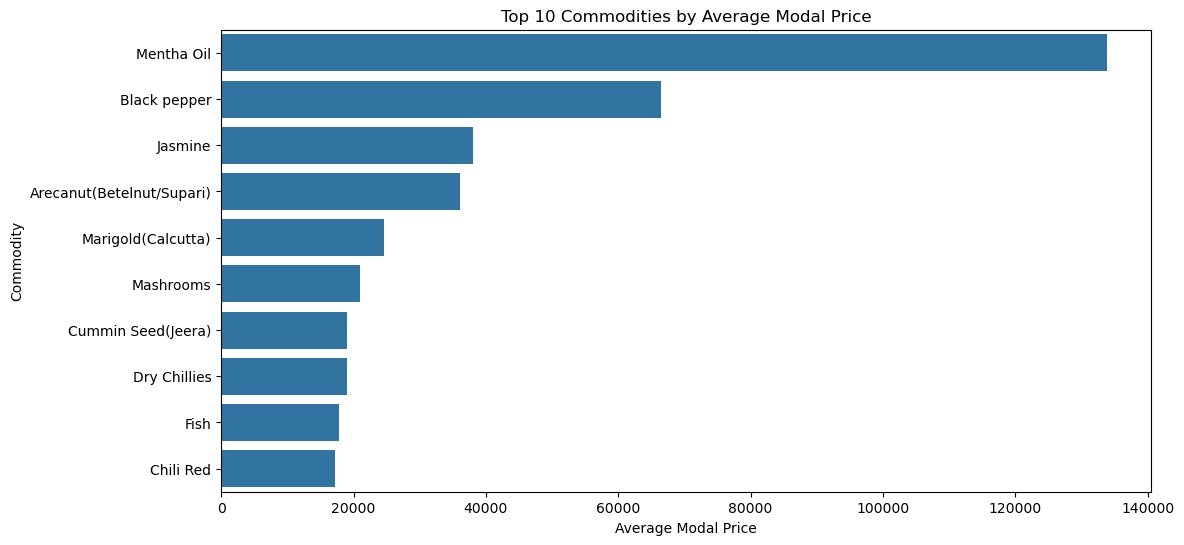

In [3]:

import matplotlib.pyplot as plt
import seaborn as sns

top = commodity_stats.nlargest(10, 'mean_price')

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top,
    x='mean_price',
    y='commodity'
)

plt.title("Top 10 Commodities by Average Modal Price")
plt.xlabel("Average Modal Price")
plt.ylabel("Commodity")
plt.show()


In [4]:

volatility = df.groupby('commodity')['modal_price'].agg(
    ['mean', 'std', 'count']
)

volatility = volatility[volatility['count'] >= 10].copy()

volatility['CV'] = (
    volatility['std'] / volatility['mean']
) * 100

volatility = volatility.sort_values(
    'CV', ascending=False
)

print(volatility.head(15))


                               mean           std  count         CV
commodity                                                          
Methi(Leaves)           3287.888889   3177.251067     18  96.634989
Tender Coconut          4384.441860   4060.390647     86  92.609066
Lime                    8019.354839   6932.067056     62  86.441705
Green Peas             10347.132075   8809.436119     53  85.138916
Spinach                 1553.580000   1249.808036     50  80.446970
Potato                  1781.511059   1307.172506    576  73.374369
Pointed gourd(Parval)   2949.035088   2059.481436     57  69.835773
Papaya(Raw)             2250.000000   1547.219729     10  68.765321
Sponge gourd            1988.199998   1336.434851     35  67.218331
Jack Fruit(Ripe)        3039.102564   1981.350507     39  65.195250
Coconut                 5337.703518   3469.754801    199  65.004637
Fish                   17733.543030  11396.083909     33  64.262871
Green Chilli            4347.873412   2638.60822

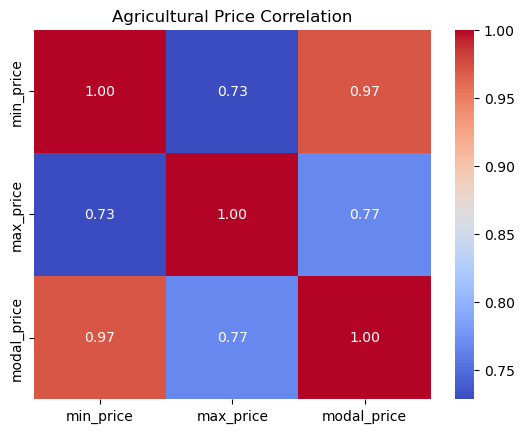

In [5]:

import seaborn as sns
import matplotlib.pyplot as plt

correlation = df[
    ['min_price', 'max_price', 'modal_price']
].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Agricultural Price Correlation")
plt.show()


In [6]:

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score

X = df[['min_price', 'max_price']]
y = df['modal_price']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()

model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, predictions)))
print("R2 Score:", r2_score(y_test, predictions))


MAE: 453.39210829531663
RMSE: 1933.2029400285787
R2 Score: 0.9527910001287617
